# Proyecto Final | Computación Flexible

**Mantenimiento predictivo para equipos industriales**

Dataset: *AI4I 2020 Predictive Maintenance* (UCI Machine Learning Repository).

Equipo 4: 
- Isaí Paz Ortiz
- Isabel Quintanar José
- Jesús Antonio Rosario Hernández

## Objetivo

Desarrollar un sistema híbrido neuro-difuso optimizado mediante algoritmos genéticos para predecir fallas en equipos industriales, manteniendo reglas interpretables y coherentes con los mecanismos físicos de falla.

Asi mismo, se busca aplicar lo aprendido a lo largo del curso, en especifico: integrar redes neuronales, sistemas difusos y algoritmos genéticos, cuidando interpretabilidad y evitando la fuga de datos.

## 0. Setup y reproducibilidad

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree


In [2]:
SEED = 42
np.random.seed(SEED)

## 1. Planteamiento

### Problema
En una línea de producción, cuando una máquina falla sin aviso se detiene la producción y la reparación es más costosa. El **mantenimiento predictivo** busca anticipar la falla usando las mediciones de la máquina (temperaturas, velocidad, torque y desgaste de la herramienta) para intervenir antes de que ocurra.

### Objetivo general
Desarrollar un sistema híbrido que combine redes neuronales, sistemas difusos y algoritmos genéticos para predecir si una máquina va a fallar, de forma que sus decisiones puedan explicarse con reglas comprensibles y coherentes con la física del proceso.

### Objetivos específicos
1. Analizar el dataset para identificar qué variables se relacionan con las fallas.
2. Preparar los datos (limpieza, variables derivadas y manejo del desbalance) sin fuga de información.
3. Construir modelos convencionales (regresión logística, árbol de decisión y Random Forest) como punto de comparación.
4. Implementar una red neuronal y un sistema difuso para predecir fallas.
5. Optimizar el sistema difuso/híbrido con un algoritmo genético (funciones de membresía y/o reglas).
6. Comparar todos los modelos con métricas adecuadas para clases desbalanceadas y explicar sus decisiones.

### Formulación del problema
Se plantea como **clasificación binaria**: el modelo responde "¿la máquina va a fallar? (1 = sí, 0 = no)" usando la columna `Machine failure`.

No se usa clasificación multiclase (predecir el *tipo* de falla) porque:
- Hay muy pocos casos de algunos tipos (TWF: 46 de 10 000).
- 24 registros tienen más de un tipo de falla al mismo tiempo.
- Las fallas RNF son aleatorias y no se pueden predecir.

Los tipos de falla se usan solo para **explicar** los errores del modelo.

### Justificación
En la industria no basta con que un modelo prediga bien: el operador necesita saber **por qué** se activa una alarma para confiar en ella y actuar. Los modelos tipo "caja negra" pueden predecir bien pero no explican sus decisiones. Los sistemas difusos explican con reglas del tipo *SI… ENTONCES…*, y el algoritmo genético permite ajustar esas reglas automáticamente a partir de los datos.

### Pregunta de investigación
¿Puede un sistema neuro-difuso optimizado con algoritmos genéticos detectar fallas con un desempeño comparable al de los modelos convencionales, manteniendo reglas interpretables y coherentes con los mecanismos físicos de falla?

### Hipótesis
El sistema híbrido optimizado alcanzará un F1 comparable al del mejor modelo base, y sus funciones de membresía optimizadas se ubicarán cerca de los umbrales físicos conocidos del proceso.

## 2. Carga y descripción del dataset

El dataset es **sintético**: fue generado para imitar datos reales de mantenimiento predictivo de un proceso de maquinado. Tiene 10 000 registros y 14 columnas.

| Variable | Descripción |
|---|---|
| `UDI`, `Product ID` | Identificadores (no se usan para predecir) |
| `Type` | Calidad del producto: L (baja), M (media), H (alta) |
| `Air temperature [K]` | Temperatura del aire |
| `Process temperature [K]` | Temperatura del proceso |
| `Rotational speed [rpm]` | Velocidad de giro |
| `Torque [Nm]` | Fuerza de giro |
| `Tool wear [min]` | Minutos de uso acumulado de la herramienta |
| `Machine failure` | **Variable objetivo**: 1 = falla, 0 = no falla |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | Tipo de falla ocurrida (ver tabla abajo) |

| Tipo | Significado |
|---|---|
| TWF | Desgaste de la herramienta |
| HDF | Falla por disipación de calor |
| PWF | Falla por potencia fuera de rango |
| OSF | Sobreesfuerzo |
| RNF | Falla aleatoria |

In [3]:
df = pd.read_csv("./dataset/ai4i2020.csv")

print(df.shape)
df.info()

(10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9

## 3. EDA

### 3.1 Tipos, nulos, duplicados, consistencia de etiquetas

In [4]:
print("Nulos totales:", df.isna().sum().sum())
print("Duplicados:", df.duplicated().sum())

Nulos totales: 0
Duplicados: 0


No hay valores faltantes ni registros duplicados, por lo que **no fue necesario imputar datos**.

In [5]:
modos = ["TWF", "HDF", "PWF", "OSF", "RNF"]

algun_modo = df[modos].any(axis=1).astype(int)
print(pd.crosstab(df["Machine failure"], algun_modo,
                  rownames=["Machine failure"], colnames=["Algún modo"]))

Algún modo          0    1
Machine failure           
0                9643   18
1                   9  330


In [6]:
cols_inspeccion = ["Type", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

# Caso A: modo activo, pero sin falla
caso_a = df[(df["Machine failure"] == 0) & algun_modo.astype(bool)]
print("Caso A:", len(caso_a))
print(caso_a[modos].sum())

# Caso B: falla sin modo registrado
caso_b = df[(df["Machine failure"] == 1) & ~algun_modo.astype(bool)]
print("\nCaso B:", len(caso_b))
print(caso_b[cols_inspeccion])

# Filas con más de un modo simultáneo
print("\nFilas multi-modo:", (df[modos].sum(axis=1) > 1).sum())

Caso A: 18
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64

Caso B: 9
     Type  Air temperature [K]  Process temperature [K]  \
1437    H                298.8                    309.9   
2749    M                299.7                    309.2   
4044    M                301.9                    310.9   
4684    M                303.6                    311.8   
5536    M                302.3                    311.8   
5941    L                300.6                    310.7   
6478    L                300.5                    309.8   
8506    L                298.4                    309.6   
9015    L                297.2                    308.1   

      Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
1437                    1439         45.2               40  
2749                    1685         28.9              179  
4044                    1419         47.7               20  
4684                    1421         44.8              101  
5536               

**Consistencia de etiquetas.** Se esperaba que `Machine failure = 1` siempre que hubiera algún tipo de falla activo. Se encontraron dos excepciones:

- **Caso A (18 registros):** tienen falla tipo RNF pero `Machine failure = 0`. Como RNF es aleatoria y el objetivo es `Machine failure`, estos registros **se conservan** sin cambios.
- **Caso B (9 registros):** tienen `Machine failure = 1` pero ningún tipo de falla registrado. Al calcular sus valores físicos (diferencia de temperatura, potencia y desgaste × torque), **ninguno cumple las condiciones de falla**: todos parecen operación normal. Se consideran errores de etiqueta y **se eliminan**, porque enseñarían al modelo que hay fallas en zonas donde la física dice que no las hay. Son solo 9 de 10 000 registros (0.09%).
- **24 registros** tienen más de un tipo de falla a la vez. No afectan a la clasificación binaria.

In [7]:
# Limpieza: eliminar fallas sin causa registrada (caso B)
df_clean = df.drop(index=caso_b.index).reset_index(drop=True)
print(df_clean.shape)
print(df_clean["Machine failure"].value_counts())

(9991, 14)
Machine failure
0    9661
1     330
Name: count, dtype: int64


Dataset limpio: **9 991 registros**, de los cuales **330 son fallas**.

### 3.2 Estadísticas descriptivas

In [8]:
features = ["Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

# Descriptivas globales
display(df_clean[features].describe().T)

# Descriptivas por clase
display(df_clean.groupby("Machine failure")[features].agg(["mean", "std"]).T)

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],9991.0,300.004634,2.000300,295.3,298.3,300.1,301.5,304.5
Process temperature [K],9991.0,310.005385,1.483990,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],9991.0,1538.804124,179.321027,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],9991.0,39.985377,9.969029,3.8,33.2,40.1,46.7,76.6
Tool wear [min],9991.0,107.942648,63.656648,0.0,53.0,108.0,162.0,253.0


Machine failure                         0            1
Air temperature [K]     mean   299.973999   300.901515
                        std      1.990748     2.073226
Process temperature [K] mean   309.995570   310.292727
                        std      1.486846     1.369004
Rotational speed [rpm]  mean  1540.260014  1496.181818
                        std    167.394734   389.590780
Torque [Nm]             mean    39.629655    50.399394
                        std      9.472080    16.457729
Tool wear [min]         mean   106.693717   144.506061
                        std     62.945790    72.939549

**Observaciones:**
- **Torque:** las fallas tienen un torque promedio mayor (50.4 vs 39.6 Nm).
- **Desgaste de herramienta:** las fallas ocurren con herramientas más gastadas (144.5 vs 106.7 min).
- **Velocidad:** el promedio es parecido, pero la variación es mucho mayor en las fallas (desv. 390 vs 167). Esto indica que las fallas ocurren en **los dos extremos**: velocidades muy bajas y muy altas.
- **Temperaturas:** por separado cambian poco entre clases.

### 3.3 Distribución de clases y modos de falla

In [9]:
print(df_clean["Machine failure"].value_counts())
print(df_clean["Machine failure"].value_counts(normalize=True))
print(df_clean[modos].sum())

Machine failure
0    9661
1     330
Name: count, dtype: int64
Machine failure
0    0.96697
1    0.03303
Name: proportion, dtype: float64
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


In [10]:
# Distribución de Type y tasa de falla por tipo
print(df_clean["Type"].value_counts(normalize=True))
print(df_clean.groupby("Type")["Machine failure"].mean())

Type
L    0.60014
M    0.29957
H    0.10029
Name: proportion, dtype: float64
Type
H    0.019960
L    0.038526
M    0.026395
Name: Machine failure, dtype: float64


**Desbalance de clases:** solo el **3.3%** de los registros son fallas. Un modelo que siempre diga "no falla" tendría 96.7% de exactitud (*accuracy*) sin detectar ninguna falla. Por eso **no se usa accuracy** como métrica principal, sino recall, precision, F1 y PR-AUC.

**Tipo de producto:** la tasa de falla baja conforme sube la calidad: L (3.9%) > M (2.6%) > H (2.0%).

### 3.4 Distribuciones por clase (falla vs no falla)

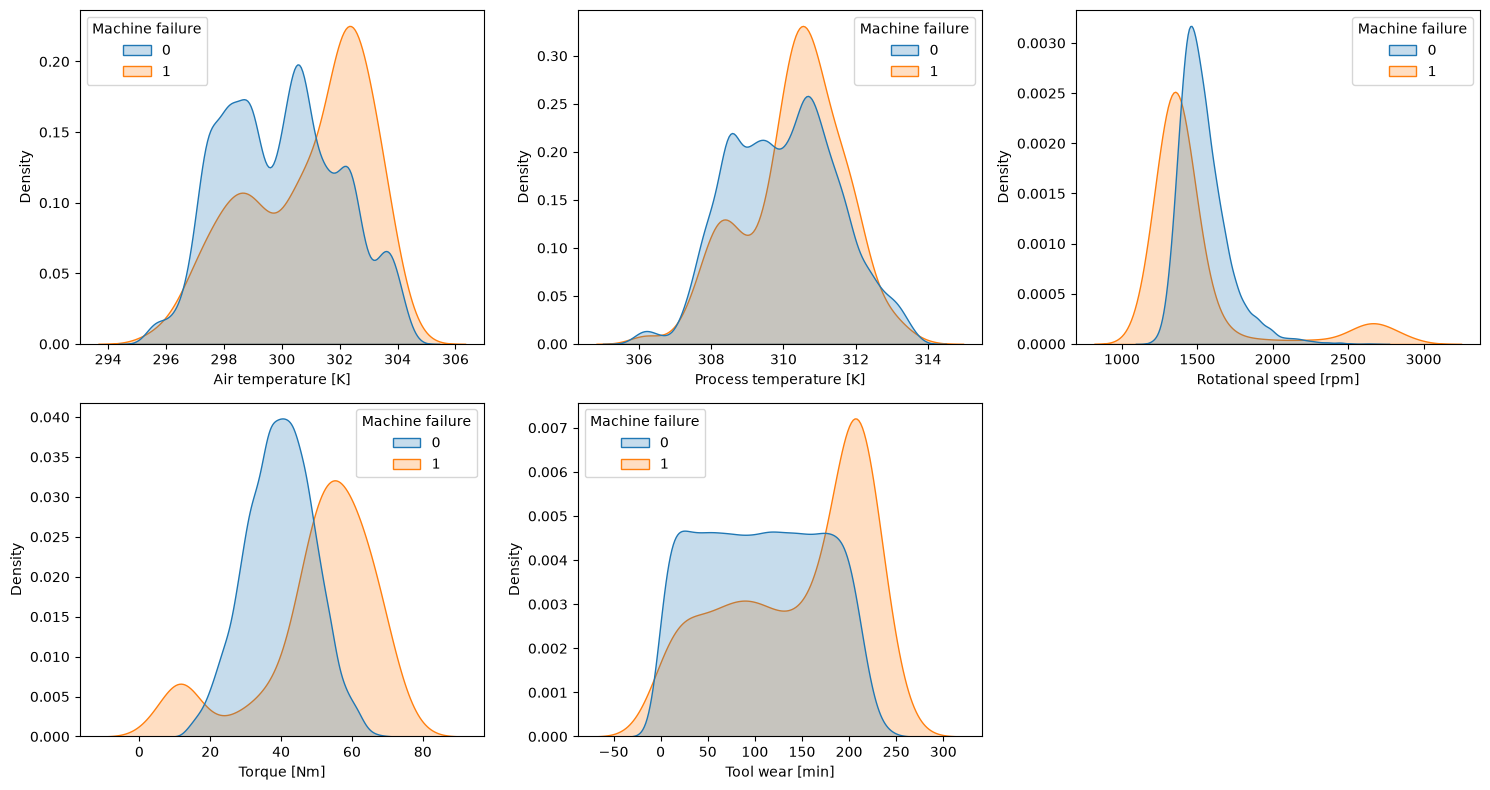

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, features):
    sns.kdeplot(data=df_clean, x=col, hue="Machine failure",
                common_norm=False, fill=True, ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

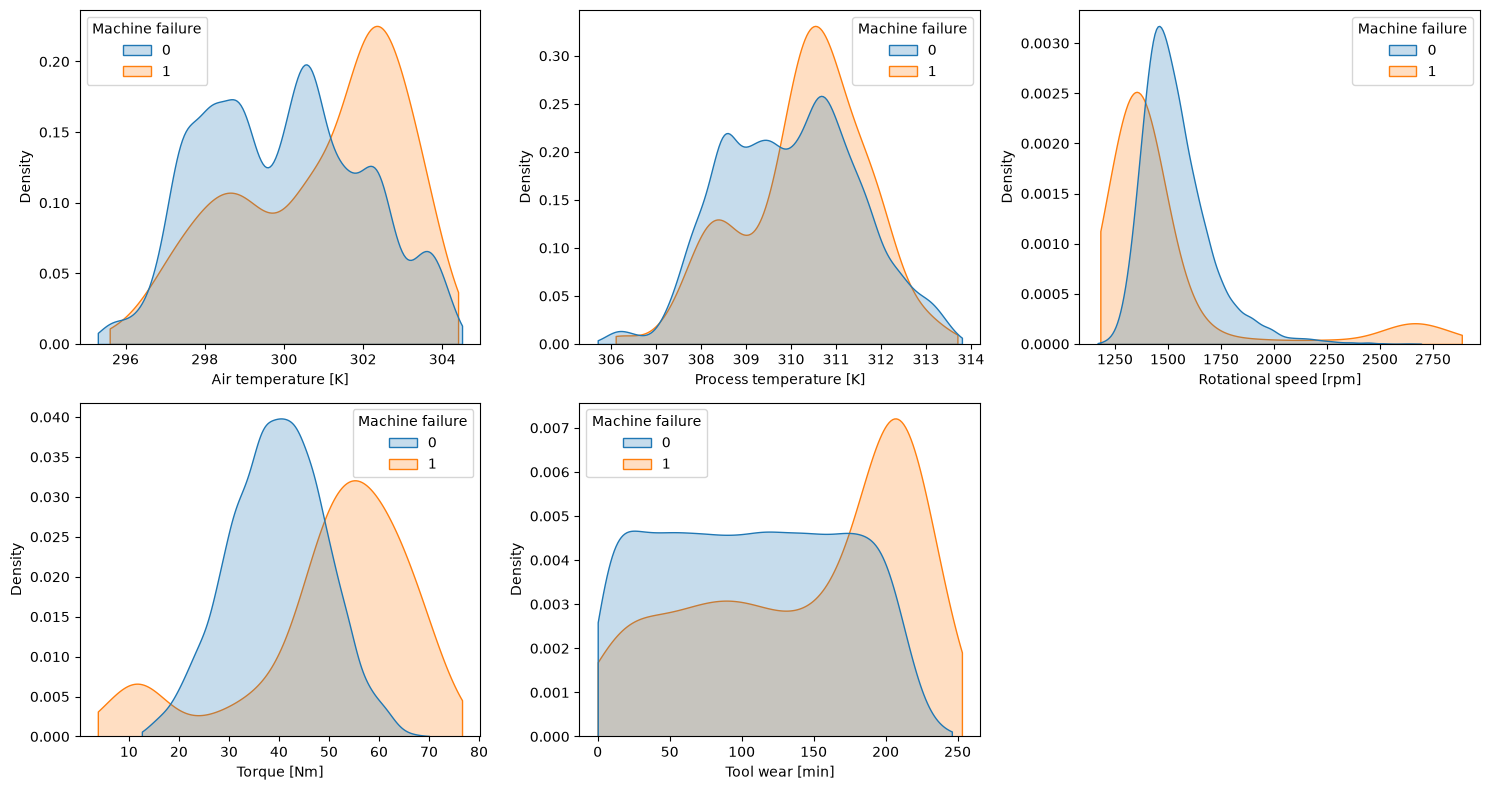

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, features):
    sns.kdeplot(data=df_clean, x=col, hue="Machine failure",
                common_norm=False, fill=True, ax=ax, cut=0)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

Las curvas muestran la distribución de cada variable para máquinas con falla (naranja) y sin falla (azul). Cada curva se normaliza por separado (`common_norm=False`) para poder comparar sus formas a pesar del desbalance.

- **Torque:** las fallas se desplazan a valores altos, con un segundo grupo pequeño en torque muy bajo (~10 Nm).
- **Velocidad:** las fallas se concentran en velocidades bajas, con un grupo pequeño en velocidades muy altas (~2600 rpm).
- **Desgaste:** las fallas tienen un pico en ~200–220 min.
- **Temperatura del aire:** las fallas tienden a temperaturas más altas.

Los grupos pequeños de torque bajo y velocidad alta son **las mismas fallas**: máquinas girando muy rápido con poca fuerza (potencia baja). Ninguna variable separa bien las clases por sí sola; las fallas dependen de **combinaciones** de variables.

### 3.5 Correlaciones

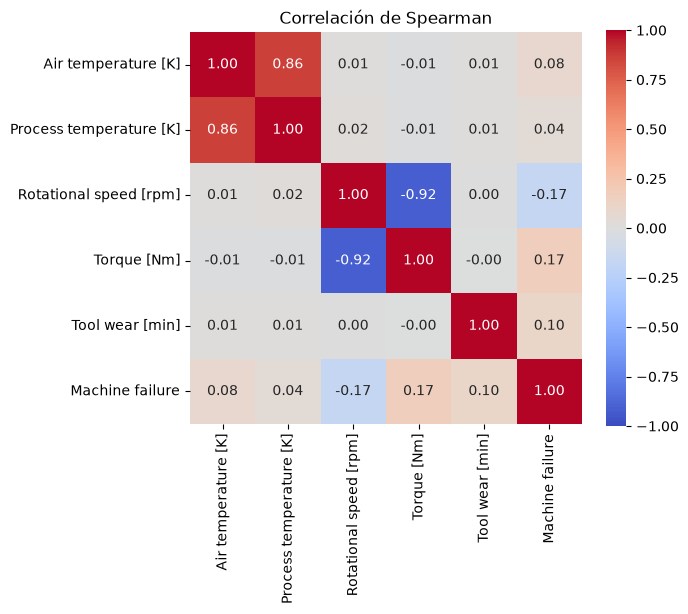

In [13]:
corr_cols = features + ["Machine failure"]
corr = df_clean[corr_cols].corr(method="spearman")

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Correlación de Spearman")
plt.tight_layout()
plt.show()

Se usó la correlación de **Spearman** porque detecta relaciones que no son líneas rectas y es menos sensible a valores extremos.

- **Temperatura del aire y del proceso (0.86):** casi redundantes. Lo importante es su **diferencia**.
- **Velocidad y torque (−0.92):** cuando una sube, la otra baja. Su producto (la **potencia**) aporta información que ninguna da por separado.
- **Correlación con la falla (0.04 a 0.17):** baja. No significa que las variables no sirvan, sino que la relación no es "más variable = más falla": por ejemplo, con la velocidad fallan los dos extremos.

### 3.6 Verificación de las reglas físicas

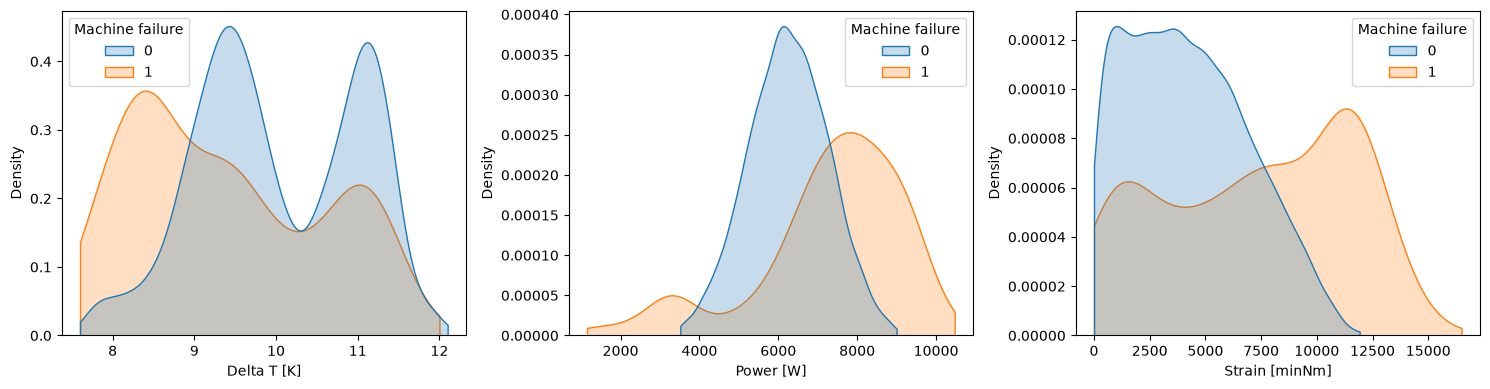

In [14]:
def agregar_variables_fisicas(data: pd.DataFrame) -> pd.DataFrame:
    out = data.copy()
    out["Delta T [K]"] = out["Process temperature [K]"] - out["Air temperature [K]"]
    omega = out["Rotational speed [rpm]"] * 2 * np.pi / 60   # rpm → rad/s
    out["Power [W]"] = out["Torque [Nm]"] * omega
    out["Strain [minNm]"] = out["Tool wear [min]"] * out["Torque [Nm]"]
    return out

eda = agregar_variables_fisicas(df_clean)
nuevas = ["Delta T [K]", "Power [W]", "Strain [minNm]"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, nuevas):
    sns.kdeplot(data=eda, x=col, hue="Machine failure",
                common_norm=False, fill=True, cut=0, ax=ax)
plt.tight_layout()
plt.show()

In [15]:
umbral_osf = eda["Type"].map({"L": 11000, "M": 12000, "H": 13000})

reglas = pd.DataFrame({
    "HDF": (eda["Delta T [K]"] < 8.6) & (eda["Rotational speed [rpm]"] < 1380),
    "PWF": (eda["Power [W]"] < 3500) | (eda["Power [W]"] > 9000),
    "OSF": eda["Strain [minNm]"] > umbral_osf,
})

for modo in reglas.columns:
    print(f"\n{modo}")
    print(pd.crosstab(reglas[modo], eda[modo],
                      rownames=["Regla se cumple"], colnames=["Flag real"]))


HDF
Flag real           0    1
Regla se cumple           
False            9876    0
True                0  115

PWF
Flag real           0   1
Regla se cumple          
False            9896   0
True                0  95

OSF
Flag real           0   1
Regla se cumple          
False            9893   0
True                0  98


Se crearon tres variables con significado físico:

| Variable | Fórmula | Relacionada con |
|---|---|---|
| `Delta T [K]` | T. proceso − T. aire | HDF |
| `Power [W]` | Torque × velocidad angular | PWF |
| `Strain [minNm]` | Desgaste × torque | OSF |

En las gráficas, estas variables **separan las fallas mucho mejor** que las originales.

Se verificaron las reglas de falla descritas por el autor del dataset:
- **HDF:** ΔT < 8.6 K **y** velocidad < 1380 rpm
- **PWF:** potencia < 3500 W **o** > 9000 W
- **OSF:** Strain > 11 000 (L), 12 000 (M), 13 000 (H)

Las tres se cumplen al **100%** (cero excepciones). TWF no se verifica porque ocurre en un momento aleatorio entre 200 y 240 min de desgaste.

## 4. Exploración no supervisada (comparativa)

*Pendiente para la segunda entrega.*

### 4.1 Codo + silueta → k para K-Means

### 4.2 K-Means vs DBSCAN vs HDBSCAN

### 4.3 ¿Los clusters capturan regímenes de falla? (tasa de falla por cluster)


## 5. Preprocesamiento


### 5.1 Eliminación de IDs y columnas con fuga


In [16]:
cols_id = ["UDI", "Product ID"]
cols_fuga = modos  # TWF, HDF, PWF, OSF, RNF
datos = df_clean.drop(columns=cols_id + cols_fuga)
print(datos.columns.tolist())

['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


- `UDI` y `Product ID` son identificadores sin significado físico.
- Los tipos de falla (`TWF`…`RNF`) se eliminan de las entradas porque se registran **después** de que ocurre la falla. Usarlos sería **fuga de datos**: el modelo vería información que no tendría en la vida real. Se conservan en `df_clean` solo para analizar errores.

### 5.2 Codificación de Type


In [17]:
datos["Type"] = datos["Type"].map({"L": 0, "M": 1, "H": 2})
print(datos["Type"].value_counts())

Type
0    5996
1    2993
2    1002
Name: count, dtype: int64


Se usa **codificación ordinal** (L = 0, M = 1, H = 2) porque el tipo representa un orden real de calidad, y los umbrales de OSF crecen en ese mismo orden. Además, mantiene una sola columna fácil de interpretar.

### 5.3 Ingeniería de características


In [18]:
datos = agregar_variables_fisicas(datos)

TARGET = "Machine failure"
feat_originales = ["Type"] + features
feat_fisicas = feat_originales + ["Delta T [K]", "Power [W]", "Strain [minNm]"]

X = datos.drop(columns=TARGET)
y = datos[TARGET]
print(X.shape, y.mean())

(9991, 9) 0.03302972675407867


Se agregan las tres variables físicas de la sección 3.6. Calcularlas antes de dividir los datos no genera fuga, porque cada fila se calcula **solo con sus propios valores**.

Se definen dos conjuntos de entradas para comparar:
- **Originales:** las 6 variables del dataset.
- **Físicas:** las originales + ΔT, potencia y Strain.

### 5.4 Split estratificado → escalado/SMOTE solo en train (Pipeline)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, "fallas:", y_train.sum())
print("Test: ", X_test.shape, "fallas:", y_test.sum())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: (7992, 9) fallas: 264
Test:  (1999, 9) fallas: 66


In [20]:
def crear_pipeline(modelo, usar_smote=True):
    pasos = [("escalado", StandardScaler())]
    if usar_smote:
        # Type es la columna 0 en ambos conjuntos de variables
        pasos.append(("smote", SMOTENC(categorical_features=[0],
                                       random_state=SEED)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)

- **División 80/20 estratificada:** el conjunto de prueba conserva el mismo 3.3% de fallas (66 casos). Se guarda **sin tocar** hasta la evaluación final.
- **Validación cruzada de 5 particiones:** todas las decisiones (modelo, variables, uso de SMOTE) se toman con los datos de entrenamiento.
- **Pipeline:** el escalado y SMOTE se ajustan solo con la parte de entrenamiento de cada partición, para que el modelo nunca "vea" los datos de validación.
- **Escalado antes de SMOTE:** SMOTE crea ejemplos usando distancias. Sin escalar, la potencia (~6000) dominaría sobre ΔT (~10).
- **SMOTENC:** variante de SMOTE que trata `Type` como categoría, para no crear valores inexistentes como "0.6".
- **Limitación:** SMOTE interpola cada columna por separado, así que en una falla sintética la potencia no coincide exactamente con torque × velocidad.

### 5.5 Selección de características


La importancia por permutación (sección 6.3) muestra que las temperaturas originales aportan casi nada cuando se incluye ΔT. La selección formal de variables se hará en la segunda entrega, para reducir el número de entradas del sistema difuso (menos entradas = menos reglas).

## 6. Modelo base


### 6.1 Regresión logística + Árbol/Random Forest


In [21]:
modelos = {
    "LogReg": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    "Árbol":  lambda: DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "RF":     lambda: RandomForestClassifier(n_estimators=300, random_state=SEED),
}
conjuntos = {"originales": feat_originales, "físicas": feat_fisicas}
scoring = {"recall": "recall", "precision": "precision", "f1": "f1",
           "pr_auc": "average_precision", "roc_auc": "roc_auc"}

In [22]:
filas = []
for nombre_m, fabrica in modelos.items():
    for nombre_c, cols in conjuntos.items():
        for smote in (False, True):
            pipe = crear_pipeline(fabrica(), usar_smote=smote)
            res = cross_validate(pipe, X_train[cols], y_train,
                                 cv=cv, scoring=scoring, n_jobs=-1)
            fila = {"modelo": nombre_m, "variables": nombre_c, "smote": smote}
            for m in scoring:
                fila[m] = res[f"test_{m}"].mean()
            fila["f1_std"] = res["test_f1"].std()
            filas.append(fila)

resultados = pd.DataFrame(filas).sort_values("f1", ascending=False)
display(resultados.round(3))

,modelo,variables,smote,recall,precision,f1,pr_auc,roc_auc,f1_std
6,Árbol,físicas,False,0.848,0.958,0.899,0.887,0.980,0.024
10,RF,físicas,False,0.837,0.963,0.895,0.922,0.990,0.027
11,RF,físicas,True,0.871,0.710,0.780,0.894,0.993,0.032
8,RF,originales,False,0.587,0.866,0.699,0.794,0.983,0.054
9,RF,originales,True,0.765,0.575,0.656,0.731,0.982,0.030
7,Árbol,físicas,True,0.917,0.427,0.582,0.827,0.986,0.024
4,Árbol,originales,False,0.330,0.873,0.476,0.555,0.920,0.049
5,Árbol,originales,True,0.890,0.316,0.465,0.491,0.952,0.020
2,LogReg,físicas,False,0.258,0.783,0.385,0.512,0.927,0.046
0,LogReg,originales,False,0.220,0.751,0.338,0.482,0.908,0.058


**Métricas usadas:**
- **Recall:** de las fallas reales, ¿cuántas detectó? (la más importante: una falla no detectada = máquina detenida).
- **Precision:** de las alarmas, ¿cuántas eran fallas reales? (si es baja, hay mantenimientos innecesarios).
- **F1:** balance entre recall y precision.
- **PR-AUC:** calidad general del modelo, recomendada para clases desbalanceadas.

**Resultados:**
1. **Las variables físicas son la mejora más grande.** El F1 del árbol sube de 0.48 a 0.90, y el de RF de 0.70 a 0.90.
2. **El árbol de profundidad 5 empata con Random Forest** (0.899 vs 0.895): un modelo legible rinde igual que uno de 300 árboles.
3. **La regresión logística falla incluso con variables físicas** (F1 = 0.39), porque las reglas de falla no son lineales: PWF ocurre en ambos extremos de potencia y HDF requiere dos condiciones a la vez.
4. **SMOTE no mejoró el F1 en ningún caso:** sube el recall pero baja mucho la precision. Con buenas variables, los modelos ya separan bien las clases. Se volverá a evaluar con la red neuronal.

**Modelos base elegidos (variables físicas, sin SMOTE):** árbol de decisión (principal, interpretable), Random Forest (referencia fuerte) y regresión logística (referencia lineal).

### 6.2 CV estratificada, métricas, matriz de confusión, curvas PR/ROC


In [23]:
finales = {
    "Árbol d=5": crear_pipeline(DecisionTreeClassifier(max_depth=5, random_state=SEED), usar_smote=False),
    "RF":        crear_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED), usar_smote=False),
    "LogReg":    crear_pipeline(LogisticRegression(max_iter=1000, random_state=SEED), usar_smote=False),
}

Xtr, Xte = X_train[feat_fisicas], X_test[feat_fisicas]
for nombre, pipe in finales.items():
    pipe.fit(Xtr, y_train)
    print(f"===== {nombre} =====")
    print(classification_report(y_test, pipe.predict(Xte), digits=3))

===== Árbol d=5 =====
              precision    recall  f1-score   support

           0      0.996     0.998     0.997      1933
           1      0.952     0.894     0.922        66

    accuracy                          0.995      1999
   macro avg      0.974     0.946     0.960      1999
weighted avg      0.995     0.995     0.995      1999

===== RF =====
              precision    recall  f1-score   support

           0      0.997     0.999     0.998      1933
           1      0.968     0.909     0.938        66

    accuracy                          0.996      1999
   macro avg      0.982     0.954     0.968      1999
weighted avg      0.996     0.996     0.996      1999

===== LogReg =====
              precision    recall  f1-score   support

           0      0.972     0.996     0.984      1933
           1      0.579     0.167     0.259        66

    accuracy                          0.968      1999
   macro avg      0.776     0.581     0.621      1999
weighted avg      

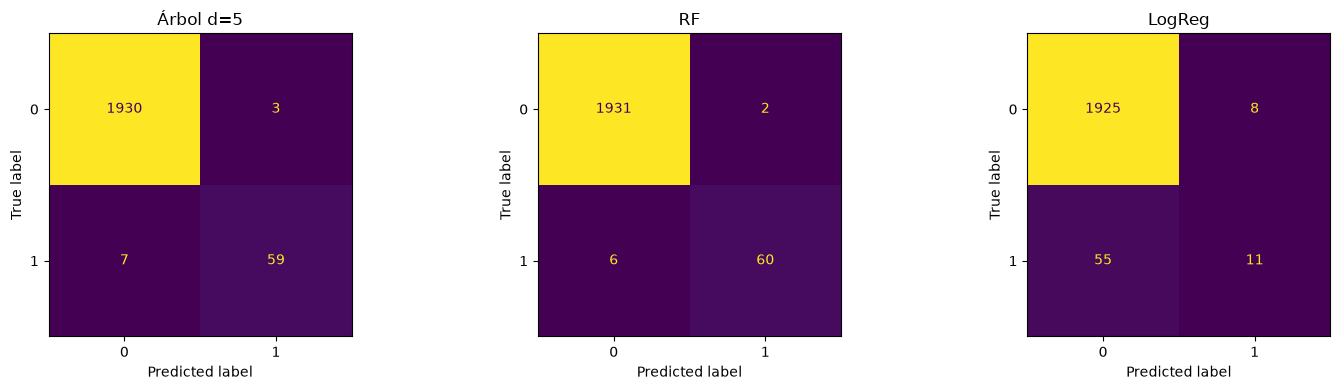

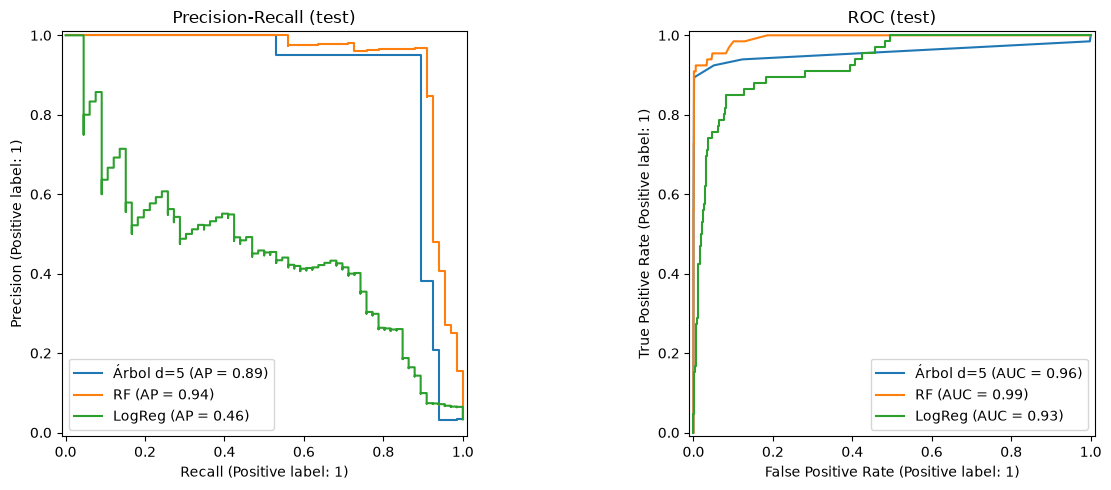

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, pipe) in zip(axes, finales.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, Xte, y_test, ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(13, 5))
for nombre, pipe in finales.items():
    PrecisionRecallDisplay.from_estimator(pipe, Xte, y_test, name=nombre, ax=ax_pr)
    RocCurveDisplay.from_estimator(pipe, Xte, y_test, name=nombre, ax=ax_roc)
ax_pr.set_title("Precision-Recall (test)")
ax_roc.set_title("ROC (test)")
plt.tight_layout()
plt.show()

In [25]:
# Recall por modo de falla (solo análisis; los modos no son entradas)
modos_test = df_clean.loc[X_test.index, ["TWF", "HDF", "PWF", "OSF"]]
print("Casos en test:", modos_test.sum().to_dict())

detec = {}
for nombre, pipe in finales.items():
    y_pred = pipe.predict(Xte)
    detec[nombre] = {m: y_pred[modos_test[m].values == 1].mean()
                     for m in modos_test.columns}
display(pd.DataFrame(detec).round(3))

Casos en test: {'TWF': 6, 'HDF': 25, 'PWF': 15, 'OSF': 21}


,Árbol d=5,RF,LogReg
TWF,0.00,0.0,0.00
HDF,0.96,1.0,0.08
PWF,1.00,1.0,0.40
OSF,1.00,1.0,0.19


**Resultados en el conjunto de prueba (66 fallas):**

| Modelo | Recall | Precision | F1 | PR-AUC | Fallas no detectadas |
|---|---|---|---|---|---|
| Árbol d=5 | 0.894 | 0.952 | 0.922 | 0.89 | 7 |
| Random Forest | 0.909 | 0.968 | 0.938 | 0.94 | 6 |
| Regresión logística | 0.167 | 0.579 | 0.259 | 0.46 | 55 |

- Los resultados son similares a los de validación cruzada: **no hay sobreajuste**.
- **¿Dónde se equivocan?** Ningún modelo detecta fallas TWF (0 de 6), porque ocurren al azar dentro de un rango de desgaste. RF detecta el 100% de HDF, PWF y OSF. Por lo tanto, el recall máximo posible es 60/66 = **0.909**, que es justo el de RF.
- La regresión logística tiene un ROC-AUC alto (0.93) pero detecta solo 11 de 66 fallas. Esto muestra que **ROC-AUC y accuracy engañan** cuando las clases están desbalanceadas.

### 6.3 Interpretabilidad del baseline (coeficientes / importancia)

In [26]:
# Árbol equivalente sin escalado, para leer umbrales en unidades físicas
arbol_raw = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(Xtr, y_train)
print("Predicciones idénticas:",
      (arbol_raw.predict(Xte) == finales["Árbol d=5"].predict(Xte)).all())

print(export_text(arbol_raw, feature_names=feat_fisicas, decimals=1))

Predicciones idénticas: True
|--- Strain [minNm] <= 10998.5
|   |--- Power [W] <= 9004.0
|   |   |--- Power [W] <= 3496.1
|   |   |   |--- class: 1
|   |   |--- Power [W] >  3496.1
|   |   |   |--- Delta T [K] <= 8.7
|   |   |   |   |--- Rotational speed [rpm] <= 1380.5
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Rotational speed [rpm] >  1380.5
|   |   |   |   |   |--- class: 0
|   |   |   |--- Delta T [K] >  8.7
|   |   |   |   |--- Tool wear [min] <= 204.5
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Tool wear [min] >  204.5
|   |   |   |   |   |--- class: 0
|   |--- Power [W] >  9004.0
|   |   |--- class: 1
|--- Strain [minNm] >  10998.5
|   |--- Type <= 0.5
|   |   |--- class: 1
|   |--- Type >  0.5
|   |   |--- Strain [minNm] <= 12128.5
|   |   |   |--- Tool wear [min] <= 173.5
|   |   |   |   |--- class: 1
|   |   |   |--- Tool wear [min] >  173.5
|   |   |   |   |--- Torque [Nm] <= 48.4
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Torque [Nm] >  4

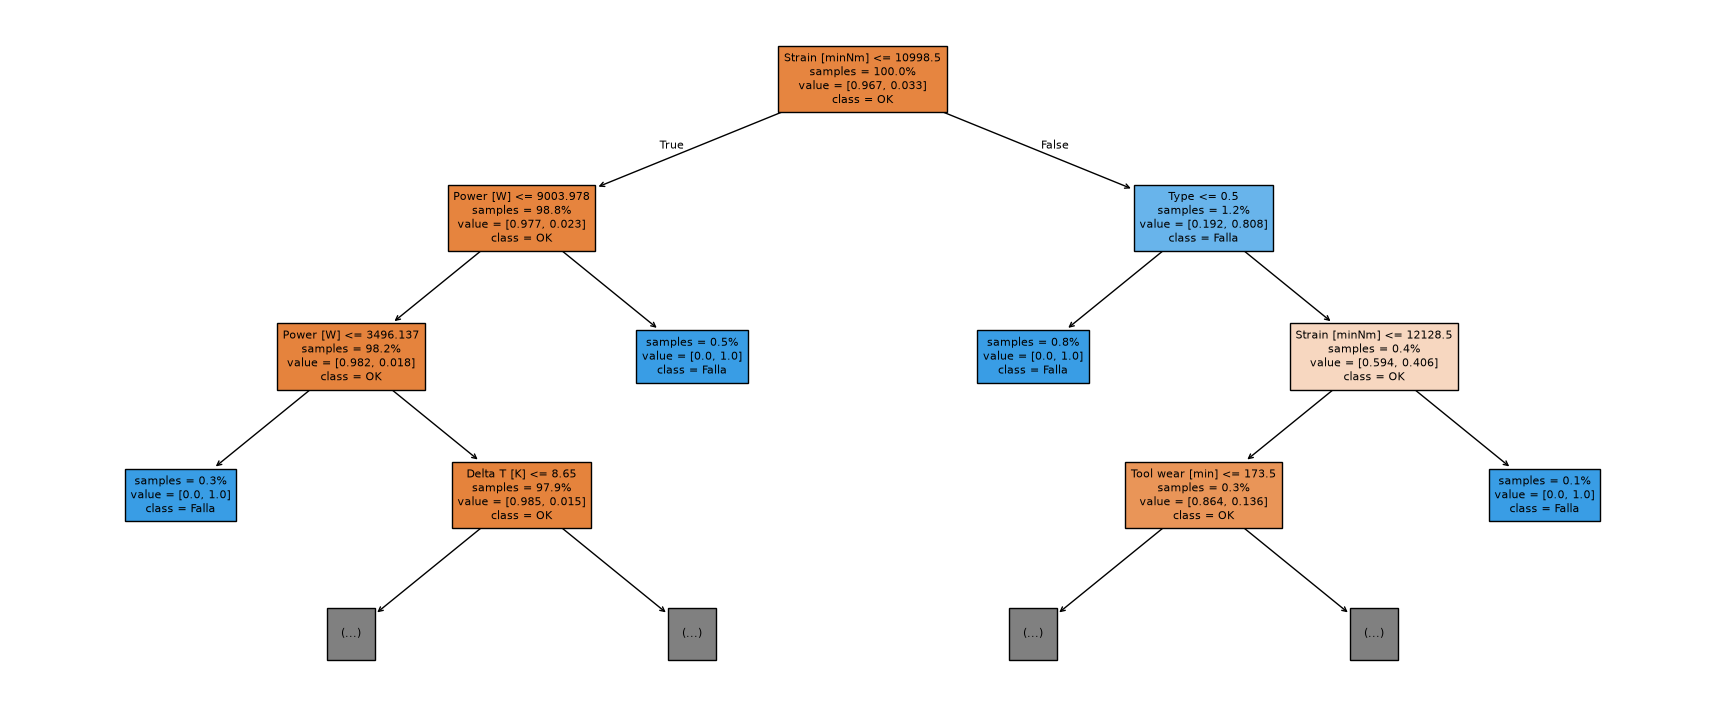

In [27]:
plt.figure(figsize=(22, 9))
plot_tree(arbol_raw, feature_names=feat_fisicas, class_names=["OK", "Falla"],
          filled=True, impurity=False, proportion=True, fontsize=8, max_depth=3)
plt.show()

In [28]:
# Coeficientes de LogReg (sobre datos escalados → magnitudes comparables)
coef = pd.Series(finales["LogReg"].named_steps["modelo"].coef_[0], index=feat_fisicas)
display(coef.sort_values(key=abs, ascending=False).round(3))

# Importancia por permutación en test (agnóstica al modelo)
imp = {}
for nombre in ["Árbol d=5", "RF"]:
    r = permutation_importance(finales[nombre], Xte, y_test, scoring="average_precision",
                               n_repeats=20, random_state=SEED, n_jobs=-1)
    imp[nombre] = pd.Series(r.importances_mean, index=feat_fisicas)
display(pd.DataFrame(imp).sort_values("RF", ascending=False).round(3))

Torque [Nm]                5.234
Power [W]                 -2.296
Rotational speed [rpm]     2.239
Tool wear [min]            0.945
Delta T [K]               -0.689
Air temperature [K]        0.270
Type                      -0.152
Process temperature [K]   -0.101
Strain [minNm]            -0.029
dtype: float64

,Árbol d=5,RF
Rotational speed [rpm],0.252,0.297
Strain [minNm],0.505,0.256
Delta T [K],0.311,0.240
Power [W],0.419,0.162
Type,0.134,0.043
Tool wear [min],0.053,0.021
Torque [Nm],0.049,0.006
Process temperature [K],0.000,0.002
Air temperature [K],0.000,-0.003


**Reglas del árbol de decisión.** Los umbrales que aprendió el árbol coinciden con las reglas físicas del dataset, **sin que se le dieran**:

| Regla física | Umbral aprendido |
|---|---|
| Strain > 11 000 (tipo L) | Strain > 10 998.5 y Type = L |
| Strain > 12 000 (tipo M) | Strain > 12 128.5 |
| Potencia < 3500 W | Power ≤ 3 496.1 |
| Potencia > 9000 W | Power > 9 004.0 |
| ΔT < 8.6 K y rpm < 1380 | Delta T ≤ 8.7 y rpm ≤ 1 380.5 |

Es decir, el árbol **redescubrió la física del proceso a partir de los datos**. Este es el estándar de interpretabilidad contra el que se comparará el sistema difuso optimizado con el AG.

**Importancia por permutación** (cuánto empeora el modelo si se desordena una variable): las más importantes son Strain, ΔT, Power y velocidad. Las temperaturas originales aportan prácticamente cero porque su información ya está en ΔT.

**Coeficientes de la regresión logística:** el mayor peso lo tiene el torque, mientras que Strain tiene un coeficiente casi nulo (−0.03), aunque es la variable más importante para el árbol. Un modelo lineal solo puede decir "más es peor" o "más es mejor", y no puede representar umbrales ni condiciones combinadas. Por eso no aprovecha las variables físicas.

## Resumen de la primera entrega
- Dataset limpio de 9 991 registros, sin valores faltantes; se eliminaron 9 errores de etiqueta.
- Problema binario con fuerte desbalance (3.3% de fallas).
- Tres variables físicas (ΔT, potencia, Strain) explican las fallas HDF, PWF y OSF con reglas exactas.
- Mejor modelo base: Random Forest (F1 = 0.938); el árbol de decisión logra casi lo mismo (F1 = 0.922) con reglas legibles.
- Las fallas TWF no se detectan: son aleatorias dentro de un rango de desgaste.

**Siguiente entrega:** red neuronal, sistema difuso (las reglas de la sección 3.6 son la base de conocimiento inicial) y optimización de sus funciones de membresía con algoritmo genético.